# Learning Objectives

- Build LLM applications for retrieval-augmented generation tasks.
- Index a folder of documents to a vector database

# Setup

In [186]:
import os
from dotenv import load_dotenv
from groq import Groq

load_dotenv(override=False)
groq_api_key = os.getenv("GROQ_API_KEY")
if not groq_api_key:
    raise RuntimeError("Set GROQ_API_KEY in the project .env file before running this notebook.")

client = Groq(api_key=groq_api_key)


In [187]:
print(client)

In [188]:
import json
import os
import chromadb
import pandas as pd
from groq import Groq
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.embeddings.sentence_transformer import SentenceTransformerEmbeddings
from langchain_community.vectorstores import Chroma


# Creating a Vector Database

## Download Raw Data

## Chunking

Once the choice of embedding model is made, we can feed the input documents to the model. However, since there are multiple pages across documents (including figures, tables) we will need a method to parse individual portions of the document that is aligned with the embedding model.

We also know that the embedding model cannot process text beyond a fixed context length (512 tokens for `gte-large`). This roughly corresponds to about 400 words or about 1 page of text. With this limitation in mind, we will transform the pdf file into chunks of text that are no more than 512 characters long (this is a conservative choice from a token perspective). An alternative method would be to chunk the file by sections in the report (e.g., risk factors, legal proceedings, safety disclosures).

A common chunking strategy is to used a fixed-size chunk as defined by the embedding model and use a small overlap between the chunks (see figure below). Note that the chunk size is number of characters and not number of tokens.


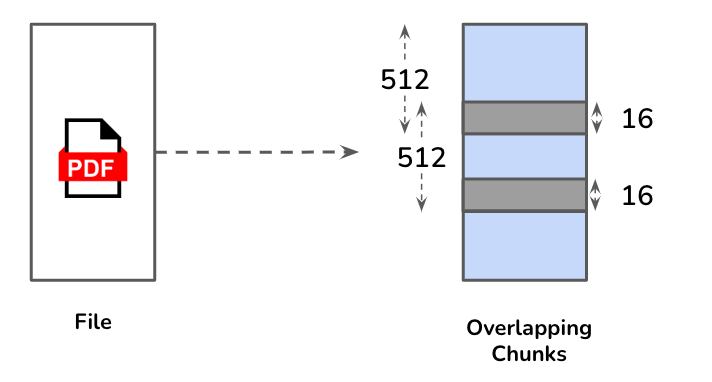

Using an overlap allows for continuity between chunks and retrieval of relevant chunks even when the information relevant to the query is present either at the beginning of the chunk or the end of the chunk.

In [189]:
pdf_loader = PyPDFLoader("tsla-20231231-gen.pdf")

In [190]:
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name='cl100k_base',
    chunk_size=512,
    chunk_overlap=16
)

In [191]:
tesla_10k_chunks = pdf_loader.load_and_split(text_splitter)

In [192]:
len(tesla_10k_chunks)

351

In [193]:
print(f"Prepared {len(tesla_10k_chunks)} document chunks.")
print(tesla_10k_chunks[0].page_content[:1000])


Prepared 351 document chunks.
UNITED	STATES
SECURITIES	AND	EXCHANGE	COMMISSION
Washington,	D.C.	20549
FORM	
10-K
(Mark	One)
x
ANNUAL	REPORT	PURSUANT	TO	SECTION	13	OR	15(d)	OF	THE	SECURITIES	EXCHANGE	ACT	OF	1934
For	the	fiscal	year	ended	
December	31
,	2023
OR
o
TRANSITION	REPORT	PURSUANT	TO	SECTION	13	OR	15(d)	OF	THE	SECURITIES	EXCHANGE	ACT	OF	1934
For	the	transition	period	from	_________	to	_________
Commission	File	Number:	
001-34756
Tesla,	Inc.
(Exact	name	of	registrant	as	specified	in	its	charter)
Delaware
91-2197729
(State	or	other	jurisdiction	of
incorporation	or	organization)
(I.R.S.	Employer
Identification	No.)
1	Tesla	Road
Austin
,	
Texas
78725
(Address	of	principal	executive	offices)
(Zip	Code)
(
512
)	
516-8177
(Registrant’s	telephone	number,	including	area	code)
Securities	registered	pursuant	to	Section	12(b)	of	the	Act:
Title	of	each	class
Trading	Symbol(s)
Name	of	each	exchange	on	which	registered
Common	stock
TSLA
The	Nasdaq	Global	Select	Market
Securities	registered	pur

## Database Creation

In [194]:
tesla_10k_collection = 'tesla-10k-2019-to-2023'

In [195]:
embedding_model = SentenceTransformerEmbeddings(model_name='all-MiniLM-L6-v2')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1642.76it/s]


In [196]:
persist_directory = "./tesla_db"
chroma_client = chromadb.PersistentClient(path=persist_directory)
collection_names = {collection.name for collection in chroma_client.list_collections()}

if tesla_10k_collection in collection_names:
    existing_collection = chroma_client.get_collection(name=tesla_10k_collection)
    if existing_collection.count() == len(tesla_10k_chunks):
        vectorstore = Chroma(
            collection_name=tesla_10k_collection,
            persist_directory=persist_directory,
            embedding_function=embedding_model,
        )
    else:
        chroma_client.delete_collection(name=tesla_10k_collection)
        vectorstore = Chroma.from_documents(
            tesla_10k_chunks,
            embedding_model,
            collection_name=tesla_10k_collection,
            persist_directory=persist_directory,
        )
else:
    vectorstore = Chroma.from_documents(
        tesla_10k_chunks,
        embedding_model,
        collection_name=tesla_10k_collection,
        persist_directory=persist_directory,
    )


In [197]:
vectorstore.persist()

In [198]:
#Loading the Chroma DB and using the retriever to retreive the chunks just for testing

In [199]:
vectorstore_persisted = Chroma(
    collection_name=tesla_10k_collection,
    persist_directory='./tesla_db',
    embedding_function=embedding_model
)

In [200]:
retriever = vectorstore_persisted.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 8},
)


In [201]:
query = "What is the annual revenue in the year 2022 ?"

In [202]:
docs = vectorstore_persisted.similarity_search(query, k=5)

In [203]:
for i, doc in enumerate(docs):
    print(f"Retrieved chunk {i+1}: \n")
    print(doc.page_content.replace('\t', ' '))
    print('\n')

Retrieved chunk 1: 

Our cash flows provided by operating activities in 2023 and 2022 were $13.26 billion and $14.72 billion, respectively, representing a decrease of $1.47
billion. Capital expenditures amounted to $8.90 billion in 2023, compared to $7.16 billion in 2022, representing an increase of $1.74 billion. Sustained
growth has allowed our business to generally fund itself, and we will continue investing in a number of capital-intensive projects and research and
development in upcoming periods.
33


Retrieved chunk 2: 

(100)%
$
203 
Not meaningful
During the year ended December 31, 2022, we recorded an impairment loss of $204 million as well as realized gains of $64 million in connection
with converting our holdings of digital assets into fiat currency. We also recorded other expenses of $36 million during the second quarter of the year
ended December 31, 2022, related to employee terminations.
Interest Income
Year Ended December 31,
2023 vs. 2022 Change
2022 vs. 2021 Change
(D

In [204]:
import json
import tiktoken

import pandas as pd

from openai import AzureOpenAI

from langchain_text_splitters import RecursiveCharacterTextSplitter

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.embeddings.sentence_transformer import (
    SentenceTransformerEmbeddings
)
from langchain_community.vectorstores import Chroma

In [205]:
model_name='openai/gpt-oss-120b' #'gpt-5.4-mini'

In [206]:
# Reuse the embedding model initialized for indexing above.


In [207]:
tesla_10k_collection = 'tesla-10k-2019-to-2023'

In [208]:
vectorstore_persisted = Chroma(
    collection_name=tesla_10k_collection,
    persist_directory='./tesla_db',
    embedding_function=embedding_model
)

In [209]:
retriever = vectorstore_persisted.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 8},
)


## RAG Q&A

### Prompt Design

In [210]:
qna_system_message = """
You are an assistant to a financial services firm who answers user queries on annual reports.
User input will have the context required by you to answer user questions.
This context will begin with the token: ###Context.
The context contains references to specific portions of a document relevant to the user query.

User questions will begin with the token: ###Question.

Please answer user questions only using the context provided in the input.
Do not mention anything about the context in your final answer. Your response should only contain the answer to the question.

If the answer is not found in the context, respond "I don't know".
"""

In [211]:
qna_user_message_template = """
###Context
Here are some documents that are relevant to the question mentioned below.
{context}

###Question
{question}
"""

### Retrieving relevant documents

In [212]:
user_input = "What is the annual revenue in the year 2022 ?"

In [213]:
relevant_document_chunks = retriever.invoke(user_input)

In [214]:
len(relevant_document_chunks)

8

In [215]:
for document in relevant_document_chunks:
    print(document.page_content.replace("\t", " "))
    break

Our cash flows provided by operating activities in 2023 and 2022 were $13.26 billion and $14.72 billion, respectively, representing a decrease of $1.47
billion. Capital expenditures amounted to $8.90 billion in 2023, compared to $7.16 billion in 2022, representing an increase of $1.74 billion. Sustained
growth has allowed our business to generally fund itself, and we will continue investing in a number of capital-intensive projects and research and
development in upcoming periods.
33


### Composing the response

In [216]:
user_input = "What is the annual revenue of Tesla in the year 2022 ?"

In [217]:
relevant_document_chunks = retriever.invoke(user_input)
context_list = [document.page_content for document in relevant_document_chunks]
context_for_query = "\n\n".join(context_list)

prompt = [
    {"role": "system", "content": qna_system_message},
    {
        "role": "user",
        "content": qna_user_message_template.format(
            context=context_for_query,
            question=user_input,
        ),
    },
]

response = client.chat.completions.create(
    model=model_name,
    messages=prompt,
    temperature=0,
)
prediction = response.choices[0].message.content
if not prediction:
    raise RuntimeError("Groq returned an empty answer.")
print(prediction.strip())


Tesla’s total revenue for 2022 was $81,462 million.


In [218]:
prompt

[{'role': 'system',
  'content': '\nYou are an assistant to a financial services firm who answers user queries on annual reports.\nUser input will have the context required by you to answer user questions.\nThis context will begin with the token: ###Context.\nThe context contains references to specific portions of a document relevant to the user query.\n\nUser questions will begin with the token: ###Question.\n\nPlease answer user questions only using the context provided in the input.\nDo not mention anything about the context in your final answer. Your response should only contain the answer to the question.\n\nIf the answer is not found in the context, respond "I don\'t know".\n'},
 {'role': 'user',
  'content': "\n###Context\nHere are some documents that are relevant to the question mentioned below.\nTesla,\tInc.\nConsolidated\tStatements\tof\tOperations\n(in\tmillions,\texcept\tper\tshare\tdata)\nYear\tEnded\tDecember\t31,\n2023\n2022\n2021\nRevenues\nAutomotive\tsales\n$\n78,509\

## Evaluation

Let us now use the LLM-as-a-judge method to check the quality of the RAG system on two parameters - retrieval and generation. We illustrate this evaluation based on the answeres generated to the question from the previous section.

In [219]:
rater_model = 'openai/gpt-oss-120b' #'gpt-5.4'

In [220]:
for model in client.models.list().data:
    print(model.id)

meta-llama/llama-prompt-guard-2-22m
openai/gpt-oss-safeguard-20b
canopylabs/orpheus-arabic-saudi
openai/gpt-oss-120b
openai/gpt-oss-20b
qwen/qwen3.8-27b
canopylabs/orpheus-v1-english
meta-llama/llama-prompt-guard-2-86m
whisper-large-v3
allam-2-7b
whisper-large-v3-turbo


To save cost, we are using GPT 3.5 itself as the judge, the ideal choice would have been GPT 4 (note that this will impact the quality of the evaluation).

In [222]:
groundedness_rater_system_message = """
You are tasked with rating AI generated answers to questions posed by users.
You will be presented a question, context used by the AI system to generate the answer and an AI generated answer to the question.
In the input, the question will begin with ###Question, the context will begin with ###Context while the AI generated answer will begin with ###Answer.

Evaluation criteria:
The task is to judge the extent to which the metric is followed by the answer.
1 - The metric is not followed at all
2 - The metric is followed only to a limited extent
3 - The metric is followed to a good extent
4 - The metric is followed mostly
5 - The metric is followed completely

Metric:
The answer should be derived only from the information presented in the context

Instructions:
1. First write down the steps that are needed to evaluate the answer as per the metric.
2. Give a step-by-step explanation if the answer adheres to the metric considering the question and context as the input.
3. Next, evaluate the extent to which the metric is followed.
4. Use the previous information to rate the answer using the evaluaton criteria and assign a score.
"""

In [223]:
relevance_rater_system_message = """
You are tasked with rating AI generated answers to questions posed by users.
You will be presented a question, context used by the AI system to generate the answer and an AI generated answer to the question.
In the input, the question will begin with ###Question, the context will begin with ###Context while the AI generated answer will begin with ###Answer.

Evaluation criteria:
The task is to judge the extent to which the metric is followed by the answer.
1 - The metric is not followed at all
2 - The metric is followed only to a limited extent
3 - The metric is followed to a good extent
4 - The metric is followed mostly
5 - The metric is followed completely

Metric:
Relevance measures how well the answer addresses the main aspects of the question, based on the context.
Consider whether all and only the important aspects are contained in the answer when evaluating relevance.

Instructions:
1. First write down the steps that are needed to evaluate the context as per the metric.
2. Give a step-by-step explanation if the context adheres to the metric considering the question as the input.
3. Next, evaluate the extent to which the metric is followed.
4. Use the previous information to rate the context using the evaluaton criteria and assign a score.
"""

In [224]:
user_message_template = """
###Question
{question}

###Context
{context}

###Answer
{answer}
"""

In [225]:
user_input = "What is the annual revenues for the years 2022 and 2023 ? Also give me the total revenue across both these years."

In [226]:
relevant_document_chunks = retriever.invoke(user_input)
context_list = [d.page_content for d in relevant_document_chunks]
context_for_query = ". ".join(context_list)

In [227]:
prompt = [
    {"role": "system", "content": qna_system_message},
    {
        "role": "user",
        "content": qna_user_message_template.format(
            context=context_for_query,
            question=user_input,
        ),
    },
]

response = client.chat.completions.create(
    model=model_name,
    messages=prompt,
    temperature=0,
)
answer = response.choices[0].message.content
if not answer:
    raise RuntimeError("Groq returned an empty answer.")
answer = answer.strip()


In [228]:
print(answer)

I don't know


In [229]:
groundedness_prompt = [
    {'role':'system', 'content': groundedness_rater_system_message},
    {'role': 'user', 'content': user_message_template.format(
        question=user_input,
        context=context_for_query,
        answer=answer
        )
    }
]

In [230]:
groundedness_prompt

[{'role': 'system',
  'content': '\nYou are tasked with rating AI generated answers to questions posed by users.\nYou will be presented a question, context used by the AI system to generate the answer and an AI generated answer to the question.\nIn the input, the question will begin with ###Question, the context will begin with ###Context while the AI generated answer will begin with ###Answer.\n\nEvaluation criteria:\nThe task is to judge the extent to which the metric is followed by the answer.\n1 - The metric is not followed at all\n2 - The metric is followed only to a limited extent\n3 - The metric is followed to a good extent\n4 - The metric is followed mostly\n5 - The metric is followed completely\n\nMetric:\nThe answer should be derived only from the information presented in the context\n\nInstructions:\n1. First write down the steps that are needed to evaluate the answer as per the metric.\n2. Give a step-by-step explanation if the answer adheres to the metric considering the q

In [231]:
response = client.chat.completions.create(
    model=rater_model,
    messages=groundedness_prompt,
    temperature=0
)

print(response.choices[0].message.content)

**Step‑by‑step procedure to evaluate the answer against the metric**

1. **Identify the information required by the question** – the annual revenues for 2022 and 2023 and the combined total.  
2. **Search the provided context for any figures that represent “revenues” for those years** (e.g., “total revenue”, “revenues”, “sales”, etc.).  
3. **Determine whether the context actually contains the needed numbers**.  
4. **Check whether the answer uses only those numbers (or explicitly states that the numbers are not present)**.  
5. **Assess if the answer adds any external knowledge, makes assumptions, or simply says “I don’t know” without referencing the context**.  
6. **Assign a rating** based on how well the answer adheres to “derived only from the information presented in the context”.

**Explanation of adherence**

- The context does **not** contain a clear line labeled “total revenue” for 2022 or 2023. It provides many financial line items (cash flow, capital expenditures, interest 

In [232]:
relevance_prompt = [
    {'role':'system', 'content': relevance_rater_system_message},
    {'role': 'user', 'content': user_message_template.format(
        question=user_input,
        context=context_for_query,
        answer=answer
        )
    }
]

In [233]:
response = client.chat.completions.create(
    model=rater_model,
    messages=relevance_prompt,
    temperature=0
)

print(response.choices[0].message.content)

**Step‑by‑step procedure to judge relevance**

1. **Identify the information the question asks for**  
   - Annual revenue for 2022.  
   - Annual revenue for 2023.  
   - The combined total of the two years.

2. **Search the supplied context for figures that represent “revenue”**  
   - Look for headings or tables labelled “Revenue”, “Total revenue”, “Net sales”, or any line that explicitly states a dollar amount that is described as revenue for the fiscal years 2022 and 2023.

3. **Determine whether the context actually contains the required numbers**  
   - If the context provides clear, separate revenue numbers for 2022 and 2023, note them.  
   - If the context only contains related but different financial metrics (e.g., cash‑flow from operations, capital expenditures, inventory values, interest income), treat those as *not* satisfying the revenue requirement.

4. **Compare the answer to the identified information**  
   - Does the answer give the two yearly revenue figures?  
   

In [236]:
import os
os.environ["LAUNCH_GRADIO"] = "1"

In [237]:
import gradio as gr

def rag_assistant(question):
    relevant_chunks = retriever.invoke(question)
    context_for_query = "\n\n".join(document.page_content for document in relevant_chunks)
    prompt = [
        {"role": "system", "content": qna_system_message},
        {
            "role": "user",
            "content": qna_user_message_template.format(
                context=context_for_query,
                question=question,
            ),
        },
    ]
    response = client.chat.completions.create(
        model=model_name,
        messages=prompt,
        temperature=0,
    )
    answer = response.choices[0].message.content
    if not answer:
        raise RuntimeError("Groq returned an empty answer.")
    return answer.strip()

with gr.Blocks() as demo:
    gr.Markdown("# Tesla 10-K RAG Assistant")
    gr.Markdown("Ask questions about Tesla's annual reports based on the indexed data.")
    with gr.Row():
        input_text = gr.Textbox(label="Your Question", placeholder="e.g., What was the revenue in 2022?")
        output_text = gr.Textbox(label="Assistant Response")
    submit_btn = gr.Button("Ask Assistant")
    submit_btn.click(fn=rag_assistant, inputs=input_text, outputs=output_text)

if os.getenv("LAUNCH_GRADIO") == "1":
    demo.launch(server_name="127.0.0.1", share=False, prevent_thread_lock=True)
else:
    print("Gradio was not started. Set LAUNCH_GRADIO=1 and run this cell to start it locally.")


* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.
